In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

In [6]:
with zipfile.ZipFile("pedestrian+in+traffic+dataset.zip", "r") as z:
    data = pd.read_csv(
        z.open("pedestrian_traffic_data/tracks.csv")
    )

print("Original dataset shape:", data.shape)
display(data.head())

Original dataset shape: (4759, 14)


,oid,timestamp,x,y,body_roll,body_pitch,body_yaw,head_roll,head_pitch,head_yaw,other_oid,other_class,other_x,other_y
0,50187,1842.4,495854.640310,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[47646, 50181, 50184, 50187]","[0, 4, 4, 4]","[495923.373133135, 495899.069769386, 495899.05...","[5405744.32136751, 5405738.47595118, 5405739.1..."
1,50187,1842.5,495854.792078,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[50181, 50187, 50184, 47646]","[4, 4, 4, 0]","[495899.234566716, 495854.792078353, 495899.22...","[5405738.39126416, 5405750.93930797, 5405739.2..."
2,50187,1842.6,495854.943847,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[47646, 50187, 50184, 50181]","[0, 4, 4, 4]","[495921.779445452, 495854.943847121, 495899.35...","[5405744.51929698, 5405750.96626812, 5405739.1..."
3,50187,1842.7,495855.095616,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[50187, 47646, 50184, 50181]","[4, 0, 4, 4]","[495855.09561589, 495920.943052671, 495899.490...","[5405750.99322827, 5405744.63008031, 5405739.1..."
4,50187,1842.8,495855.256935,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[50187, 50184, 50181, 47646]","[4, 4, 4, 0]","[495855.256935427, 495899.585908147, 495899.72...","[5405751.02150176, 5405739.0332702, 5405738.08..."


In [7]:
df = data.copy()

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Column names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (4759, 14)
Column names:
['oid', 'timestamp', 'x', 'y', 'body_roll', 'body_pitch', 'body_yaw', 'head_roll', 'head_pitch', 'head_yaw', 'other_oid', 'other_class', 'other_x', 'other_y']


,oid,timestamp,x,y,body_roll,body_pitch,body_yaw,head_roll,head_pitch,head_yaw,other_oid,other_class,other_x,other_y
0,50187,1842.4,495854.640310,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[47646, 50181, 50184, 50187]","[0, 4, 4, 4]","[495923.373133135, 495899.069769386, 495899.05...","[5405744.32136751, 5405738.47595118, 5405739.1..."
1,50187,1842.5,495854.792078,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[50181, 50187, 50184, 47646]","[4, 4, 4, 0]","[495899.234566716, 495854.792078353, 495899.22...","[5405738.39126416, 5405750.93930797, 5405739.2..."
2,50187,1842.6,495854.943847,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[47646, 50187, 50184, 50181]","[0, 4, 4, 4]","[495921.779445452, 495854.943847121, 495899.35...","[5405744.51929698, 5405750.96626812, 5405739.1..."
3,50187,1842.7,495855.095616,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[50187, 47646, 50184, 50181]","[4, 0, 4, 4]","[495855.09561589, 495920.943052671, 495899.490...","[5405750.99322827, 5405744.63008031, 5405739.1..."
4,50187,1842.8,495855.256935,5.405751e+06,NaN,NaN,NaN,NaN,NaN,NaN,"[50187, 50184, 50181, 47646]","[4, 4, 4, 0]","[495855.256935427, 495899.585908147, 495899.72...","[5405751.02150176, 5405739.0332702, 5405738.08..."


In [8]:
print("Dataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe().T)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4759 entries, 0 to 4758
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   oid          4759 non-null   int64  
 1   timestamp    4759 non-null   float64
 2   x            4759 non-null   float64
 3   y            4759 non-null   float64
 4   body_roll    2061 non-null   float64
 5   body_pitch   2061 non-null   float64
 6   body_yaw     2061 non-null   float64
 7   head_roll    2061 non-null   float64
 8   head_pitch   2061 non-null   float64
 9   head_yaw     2061 non-null   float64
 10  other_oid    4759 non-null   str    
 11  other_class  4759 non-null   str    
 12  other_x      4759 non-null   str    
 13  other_y      4759 non-null   str    
dtypes: float64(9), int64(1), str(4)
memory usage: 2.0 MB

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
oid,4759.0,3.615895e+04,15992.323879,7.682000e+03,1.934800e+04,4.205400e+04,4.965400e+04,5.094300e+04
timestamp,4759.0,1.169679e+03,800.496866,2.175000e+02,3.175000e+02,9.254000e+02,1.837850e+03,2.650800e+03
x,4759.0,4.960708e+05,109.830020,4.958135e+05,4.960086e+05,4.960628e+05,4.961575e+05,4.963313e+05
y,4759.0,5.405964e+06,176.385632,5.405731e+06,5.405741e+06,5.406074e+06,5.406116e+06,5.406147e+06
body_roll,2061.0,3.040144e-01,1.362820,-7.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.080000e+01
body_pitch,2061.0,-7.118175e-01,2.263132,-1.833420e+01,0.000000e+00,0.000000e+00,0.000000e+00,7.200000e+00
body_yaw,2061.0,1.905601e+02,80.499321,0.000000e+00,1.336000e+02,1.920000e+02,2.472000e+02,3.580000e+02
head_roll,2061.0,-2.538099e-01,3.513400,-2.800000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.878770e+01
head_pitch,2061.0,-1.086118e+00,5.660005,-2.518520e+01,-1.725930e+00,0.000000e+00,0.000000e+00,1.943210e+01
head_yaw,2061.0,1.863702e+02,77.836386,0.000000e+00,1.492000e+02,1.856870e+02,2.332000e+02,3.592590e+02


In [9]:
print("Missing Values:")
display(df.isnull().sum())

print("\nMissing Values Percentage:")
display((df.isnull().sum() / len(df) * 100).round(2))

Missing Values:


oid               0
timestamp         0
x                 0
y                 0
body_roll      2698
body_pitch     2698
body_yaw       2698
head_roll      2698
head_pitch     2698
head_yaw       2698
other_oid         0
other_class       0
other_x           0
other_y           0
dtype: int64


Missing Values Percentage:


oid             0.00
timestamp       0.00
x               0.00
y               0.00
body_roll      56.69
body_pitch     56.69
body_yaw       56.69
head_roll      56.69
head_pitch     56.69
head_yaw       56.69
other_oid       0.00
other_class     0.00
other_x         0.00
other_y         0.00
dtype: float64

In [10]:
numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
oid            0
timestamp      0
x              0
y              0
body_roll      0
body_pitch     0
body_yaw       0
head_roll      0
head_pitch     0
head_yaw       0
other_oid      0
other_class    0
other_x        0
other_y        0
dtype: int64


In [11]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Dataset shape after removing duplicates: (4759, 14)


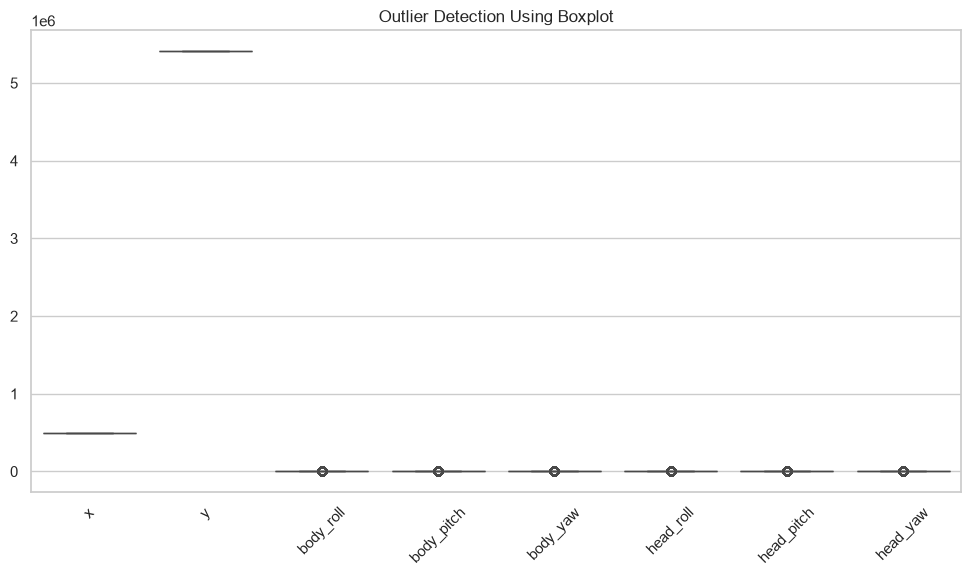

In [12]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[[
    "x", "y",
    "body_roll", "body_pitch", "body_yaw",
    "head_roll", "head_pitch", "head_yaw"
]])

plt.title("Outlier Detection Using Boxplot")
plt.xticks(rotation=45)
plt.show()

In [13]:
def cap_outliers_iqr(dataframe):

    dataframe = dataframe.copy()

    columns = [
        "x", "y",
        "body_roll", "body_pitch", "body_yaw",
        "head_roll", "head_pitch", "head_yaw"
    ]

    for column in columns:

        q1 = dataframe[column].quantile(0.25)
        q3 = dataframe[column].quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        dataframe[column] = dataframe[column].clip(
            lower=lower,
            upper=upper
        )

    return dataframe


df = cap_outliers_iqr(df)

print("Outlier treatment completed.")

Outlier treatment completed.


In [14]:
print("Unique Pedestrian IDs:")
print(df["oid"].nunique())

print("\nTotal Records:")
print(len(df))

print("\nPedestrian ID Count:")
print(df["oid"].value_counts().head(10))

Unique Pedestrian IDs:
45

Total Records:
4759

Pedestrian ID Count:
oid
39406    198
19339    177
19348    155
47946    152
19340    150
20713    149
19349    149
50943    145
40211    145
47949    134
Name: count, dtype: int64


In [15]:
df = df.sort_values(
    by=["oid", "timestamp"]
).copy()

df["dx"] = df.groupby("oid")["x"].diff()
df["dy"] = df.groupby("oid")["y"].diff()

df["dt"] = df.groupby("oid")["timestamp"].diff()

df["distance"] = np.sqrt(
    df["dx"]**2 + df["dy"]**2
)

df["speed"] = df["distance"] / df["dt"].replace(0, np.nan)

print("Speed calculation completed.")

display(df[[
    "oid", "timestamp", "x", "y", "distance", "speed"
]].head(10))

Speed calculation completed.


,oid,timestamp,x,y,distance,speed
3669,7682,309.9,496182.407356,5.405731e+06,NaN,NaN
3670,7682,310.0,496182.301754,5.405731e+06,0.150685,1.506848
3671,7682,310.1,496182.196345,5.405731e+06,0.150359,1.503587
3672,7682,310.2,496182.090936,5.405731e+06,0.150359,1.503587
3673,7682,310.3,496181.985526,5.405731e+06,0.150359,1.503587
3674,7682,310.4,496181.880117,5.405732e+06,0.150359,1.503587
3675,7682,310.5,496181.774708,5.405732e+06,0.150359,1.503587
3676,7682,310.6,496181.633764,5.405732e+06,0.170375,1.703746
3677,7682,310.7,496181.514324,5.405732e+06,0.136665,1.366652
3678,7682,310.8,496181.403335,5.405732e+06,0.163727,1.637273


In [16]:
df["acceleration"] = (
    df.groupby("oid")["speed"].diff()
    / df["dt"].replace(0, np.nan)
)

print("Acceleration calculated.")

display(df[[
    "oid", "speed", "acceleration"
]].head(10))

Acceleration calculated.


,oid,speed,acceleration
3669,7682,NaN,NaN
3670,7682,1.506848,NaN
3671,7682,1.503587,-3.260942e-02
3672,7682,1.503587,6.529910e-08
3673,7682,1.503587,6.652501e-07
3674,7682,1.503587,-7.305407e-07
3675,7682,1.503587,-4.089207e-09
3676,7682,1.703746,2.001590e+00
3677,7682,1.366652,-3.370940e+00
3678,7682,1.637273,2.706210e+00


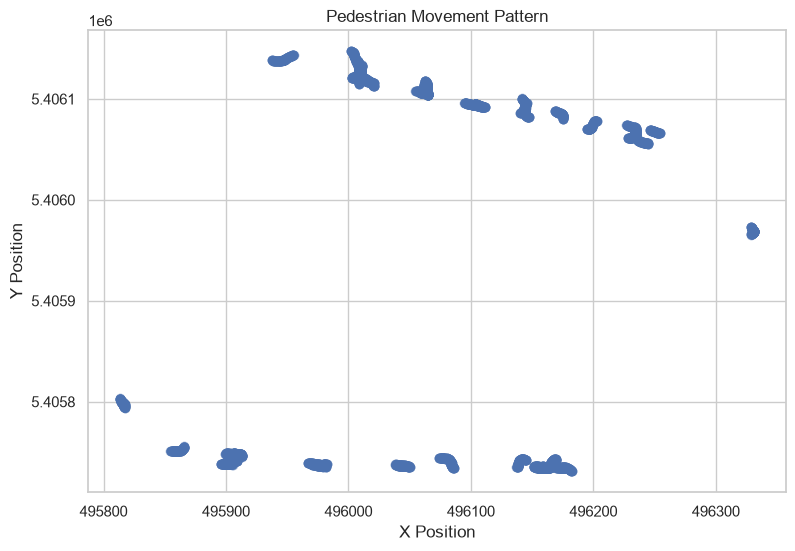

In [17]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["x"],
    df["y"],
    alpha=0.5
)

plt.title("Pedestrian Movement Pattern")
plt.xlabel("X Position")
plt.ylabel("Y Position")

plt.show()

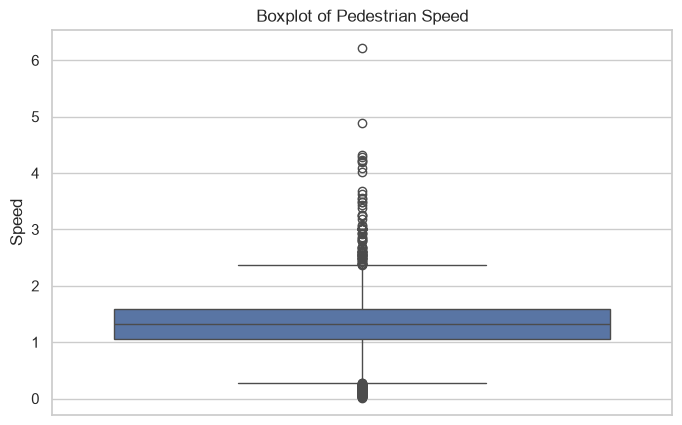

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="speed")

plt.title("Boxplot of Pedestrian Speed")
plt.ylabel("Speed")
plt.show()

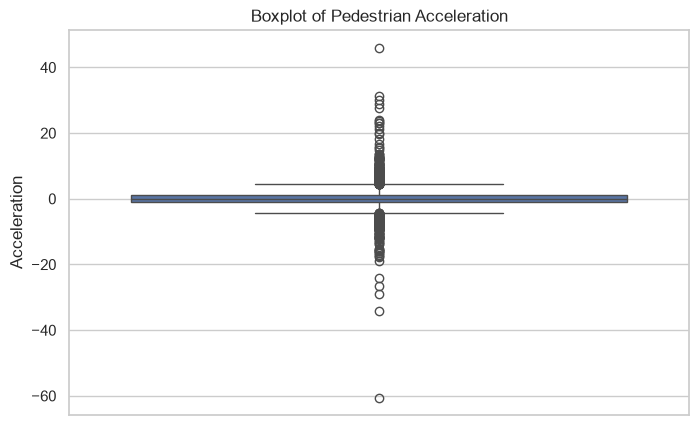

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y="acceleration")

plt.title("Boxplot of Pedestrian Acceleration")
plt.ylabel("Acceleration")
plt.show()

In [20]:
pedestrian_features = df.groupby("oid").agg({
    "speed": "mean",
    "acceleration": "mean",
    "body_yaw": "mean",
    "head_yaw": "mean",
    "distance": "mean"
}).reset_index()

pedestrian_features = pedestrian_features.replace(
    [np.inf, -np.inf], np.nan
)

pedestrian_features = pedestrian_features.dropna()

print("Pedestrian feature dataset:")
display(pedestrian_features.head())

Pedestrian feature dataset:


,oid,speed,acceleration,body_yaw,head_yaw,distance
0,7682,1.660117,0.002659,192.0,185.687,0.166012
1,7683,1.065858,0.092072,192.0,185.687,0.106586
2,7684,1.358343,0.148217,192.0,185.687,0.135834
3,8072,1.507158,-0.036949,192.0,185.687,0.150716
4,8075,1.542485,-0.104122,192.0,185.687,0.154249


In [21]:
X = pedestrian_features.drop(columns=["oid"])

print("Independent variables:", X.shape)

display(X.head())

Independent variables: (45, 5)


,speed,acceleration,body_yaw,head_yaw,distance
0,1.660117,0.002659,192.0,185.687,0.166012
1,1.065858,0.092072,192.0,185.687,0.106586
2,1.358343,0.148217,192.0,185.687,0.135834
3,1.507158,-0.036949,192.0,185.687,0.150716
4,1.542485,-0.104122,192.0,185.687,0.154249


In [22]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")

Feature scaling completed.


In [24]:
RANDOM_STATE = 42

In [25]:
model = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=10
)

pedestrian_features["Cluster"] = model.fit_predict(X_scaled)


In [26]:
pedestrian_features["Cluster"] = model.predict(X_scaled)

print("Cluster predictions:")

display(pedestrian_features.head(10))

Cluster predictions:


,oid,speed,acceleration,body_yaw,head_yaw,distance,Cluster
0,7682,1.660117,0.002659,192.0,185.687,0.166012,2
1,7683,1.065858,0.092072,192.0,185.687,0.106586,1
2,7684,1.358343,0.148217,192.0,185.687,0.135834,0
3,8072,1.507158,-0.036949,192.0,185.687,0.150716,2
4,8075,1.542485,-0.104122,192.0,185.687,0.154249,2
5,8217,1.267499,0.011702,192.0,185.687,0.126750,1
6,9776,1.076602,-0.047448,192.0,185.687,0.107660,1
7,10253,1.555711,-0.011101,192.0,185.687,0.155571,2
8,19339,1.264911,-0.015800,192.0,185.687,0.126491,1
9,19340,1.628762,0.018280,192.0,185.687,0.162876,2


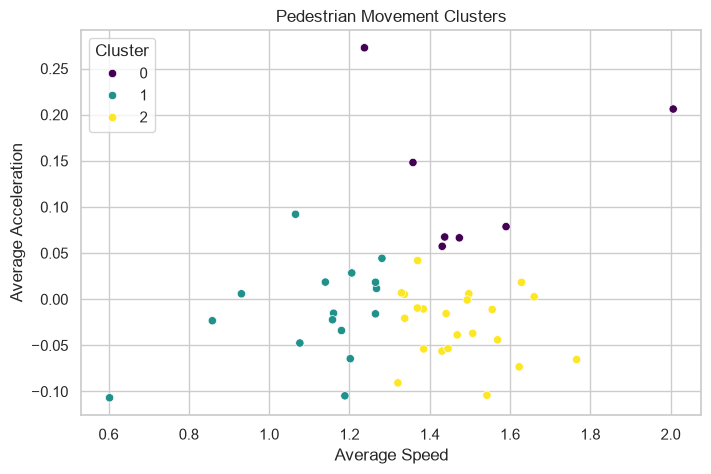

In [27]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=pedestrian_features,
    x="speed",
    y="acceleration",
    hue="Cluster",
    palette="viridis"
)

plt.title("Pedestrian Movement Clusters")
plt.xlabel("Average Speed")
plt.ylabel("Average Acceleration")
plt.show()

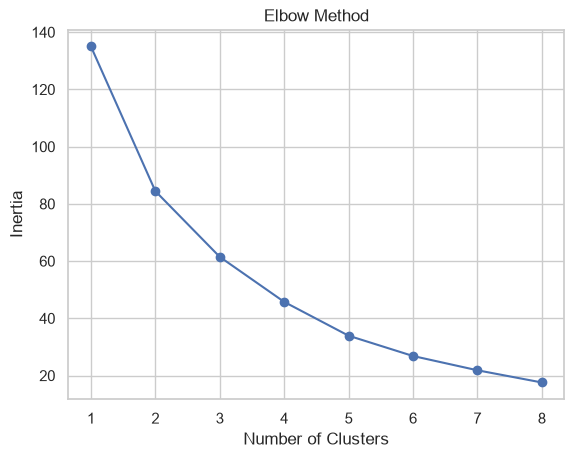

In [34]:
inertia = []

for k in range(1, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 9), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

Cluster
4    20
0    19
1     3
3     2
2     1
Name: count, dtype: int64


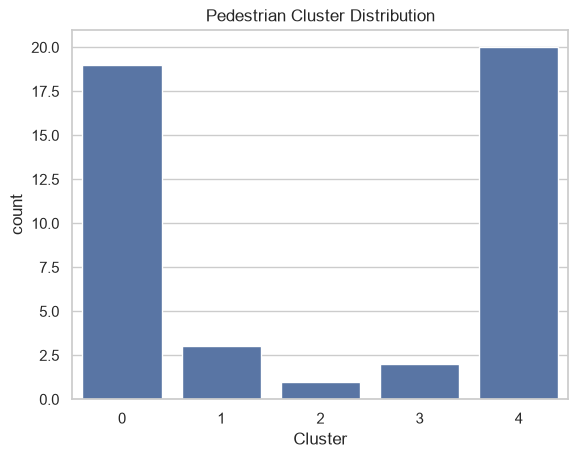

In [35]:
print(pedestrian_features["Cluster"].value_counts())

sns.countplot(data=pedestrian_features, x="Cluster")
plt.title("Pedestrian Cluster Distribution")
plt.show()

In [36]:
print(pedestrian_features.groupby("Cluster").mean(numeric_only=True))

                  oid     speed  acceleration  body_yaw  head_yaw  distance
Cluster                                                                    
0        35883.263158  1.523479     -0.013491     192.0   185.687  0.152348
1        39438.666667  0.797459     -0.041390     192.0   185.687  0.079746
2        50582.000000  2.006503      0.206167     192.0   185.687  0.200650
3        28905.000000  1.297913      0.210380     192.0   185.687  0.129791
4        37703.250000  1.245265     -0.008365     192.0   185.687  0.124527


In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    scores.append((k, score))

for k, score in scores:
    print("Clusters:", k, "| Silhouette Score:", round(score, 4))

Clusters: 2 | Silhouette Score: 0.3608
Clusters: 3 | Silhouette Score: 0.3467
Clusters: 4 | Silhouette Score: 0.359
Clusters: 5 | Silhouette Score: 0.3639
Clusters: 6 | Silhouette Score: 0.2891
Clusters: 7 | Silhouette Score: 0.3038
Clusters: 8 | Silhouette Score: 0.3111


In [38]:
best_k = max(scores, key=lambda x: x[1])

print("Best Number of Clusters:", best_k[0])
print("Best Silhouette Score:", round(best_k[1], 4))

Best Number of Clusters: 5
Best Silhouette Score: 0.3639


In [39]:
final_model = KMeans(
    n_clusters=best_k[0],
    random_state=42,
    n_init=10
)

pedestrian_features["Cluster"] = final_model.fit_predict(X_scaled)

print("Final Silhouette Score:", round(best_k[1], 4))

Final Silhouette Score: 0.3639
